In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import arch as arch
import matplotlib.pyplot as plt
import seaborn as sd

In [2]:
Infosys=yf.download('INFY.NS',period='10y')['Close']
Infosys=Infosys.rename(columns={'INFY.NS':'Price'})
Infosys['Return']=Infosys['Price'].pct_change().fillna(0)*100

[*********************100%***********************]  1 of 1 completed


In [3]:
TARCH_Model=arch.arch_model(Infosys['Return'],p=1,q=1,o=1,vol='GARCH')
TARCH_Result=TARCH_Model.fit(disp='off')
print('\n             TARCH-Model Summary for Infosys')
TARCH_Result.summary()



             TARCH-Model Summary for Infosys


<class 'statsmodels.iolib.summary.Summary'>
"""
                   Constant Mean - GJR-GARCH Model Results                    
==============================================================================
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -4707.54
Distribution:                  Normal   AIC:                           9425.09
Method:            Maximum Likelihood   BIC:                           9454.15
                                        No. Observations:                 2472
Date:                Fri, Oct 30 2026   Df Residuals:                     2471
Time:                        12:54:41   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0845  3.103e-02      2.723  6.464e-03 [2.368e-02,  0.145]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.3040      0.209      1.454      0.146    [ -0.106,  0.714]
alpha[1]       0.0641  3.534e-02      1.815  6.956e-02 [-5.132e-03,  0.133]
gamma[1]       0.0751  5.896e-02      1.273      0.203 [-4.048e-02,  0.191]
beta[1]        0.7951      0.117      6.799  1.055e-11    [  0.566,  1.024]
===========================================================================

Covariance estimator: robust
"""

In [4]:
Volatility=pd.DataFrame({'Real Volatility':Infosys['Return'].abs(),
                         'TARCH Volatility':TARCH_Result.conditional_volatility})

In [5]:
Day_ahead=30
Simulations=10000
Forecast=TARCH_Result.forecast(horizon=Day_ahead,method='simulation',simulations=Simulations)
Expected_Variance=Forecast.variance.iloc[-1]
Expected_Volatility=np.sqrt(Expected_Variance)

In [6]:
Simulated_Variance_Paths=Forecast.simulations.variances[-1]
simulated_volatility=np.sqrt(Simulated_Variance_Paths)

In [7]:
Simulated_Variance=Simulated_Variance_Paths.T
Simulated_Volatility=np.sqrt(Simulated_Variance)
Log_Return=np.log(Infosys['Price']/Infosys['Price'].shift(1)).dropna()
u=Log_Return.mean()

In [8]:
Z=np.random.normal(0,1,(Day_ahead,Simulations))

In [9]:
Price=np.zeros((Day_ahead,Simulations))
Last_Actual_Price=Infosys['Price'].iloc[-1]
Price[0]=Last_Actual_Price

In [10]:
for i in range(1,Day_ahead):
    sigma_i=Simulated_Volatility[i]/100 
    Drift_i=u-(0.5*sigma_i**2)
    Daily_Return_i=np.exp(Drift_i+sigma_i*Z[i])
    Price[i]=Price[i-1]*Daily_Return_i

In [11]:
mean_path=Price.mean(axis=1)

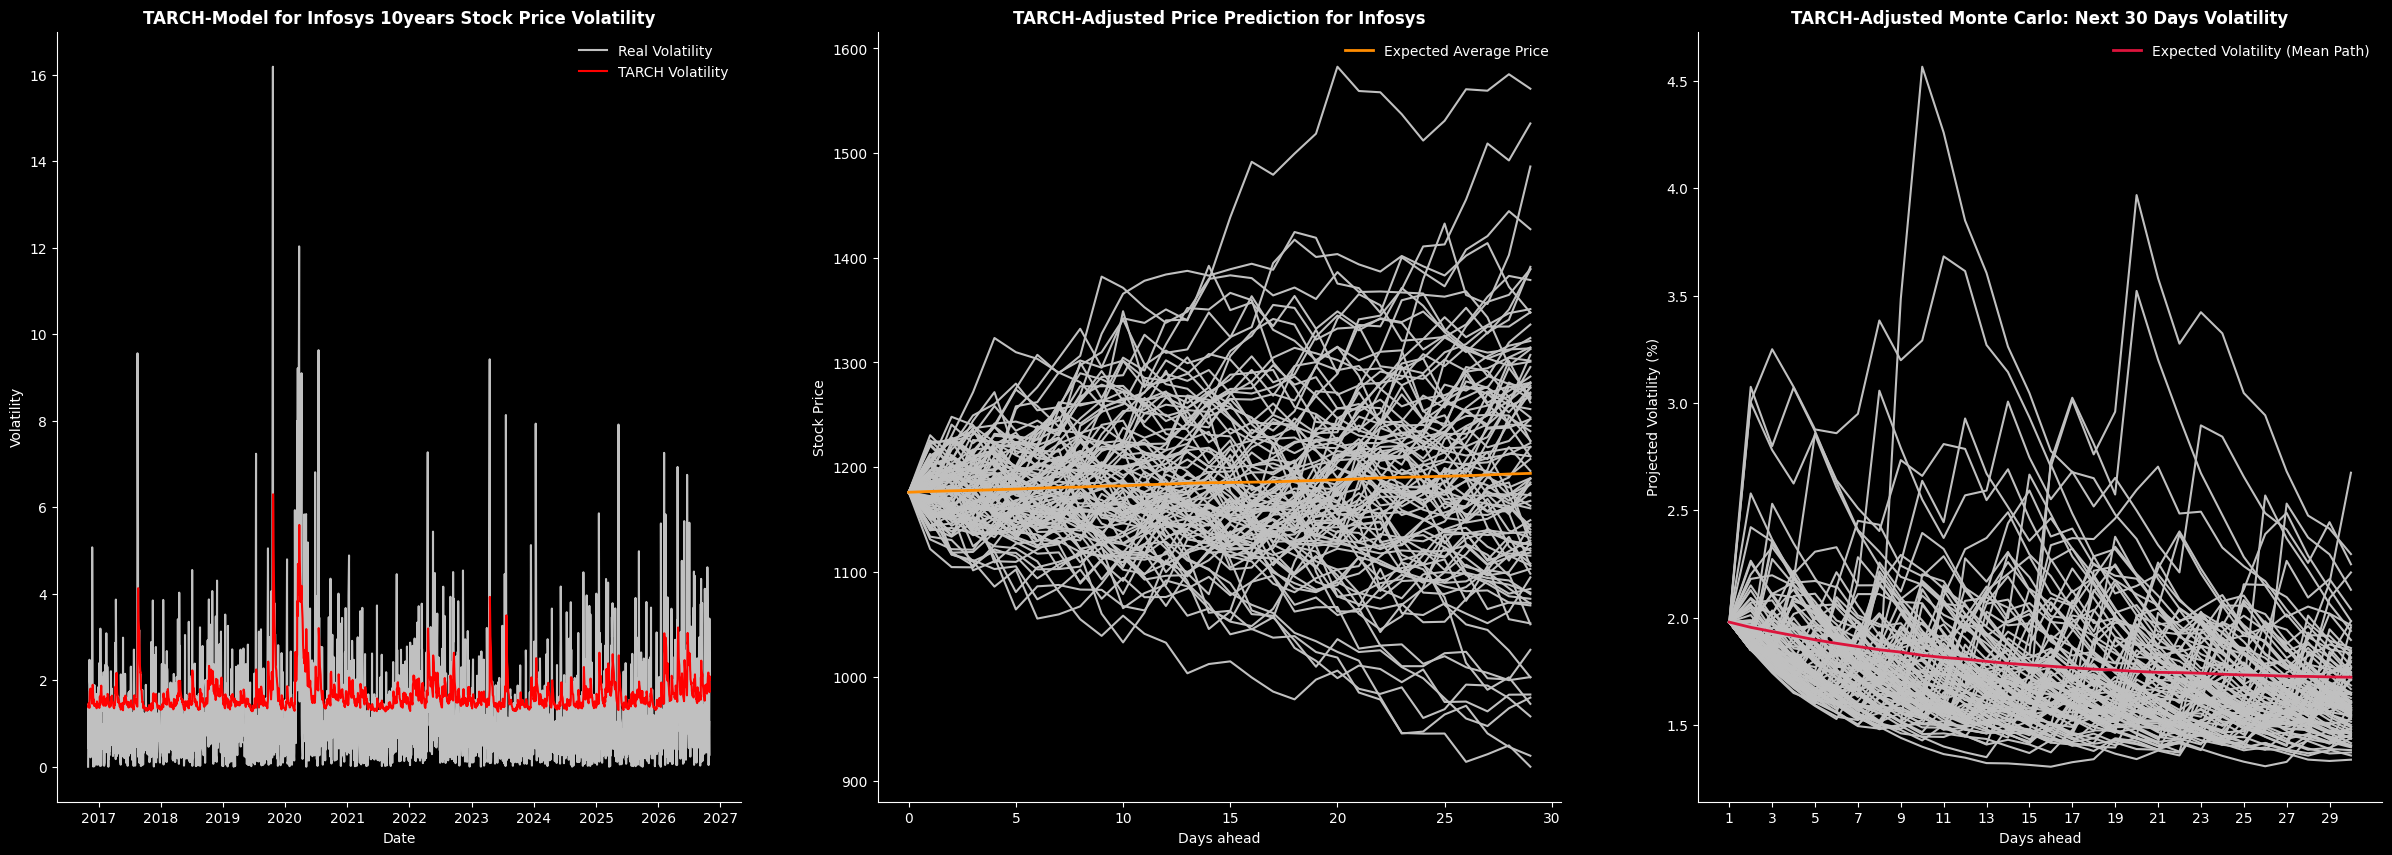

In [28]:
plt.style.use('dark_background')
fig, (ax0,ax1,ax2) = plt.subplots(1,3,figsize=(30,10))
sd.lineplot(Volatility,dashes=False,palette={'Real Volatility':'silver','TARCH Volatility':'red'},ax=ax0)
ax0.set_title('TARCH-Model for Infosys 10years Stock Price Volatility',fontsize=12,fontweight='bold')
ax0.legend(frameon=False)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.set_ylabel('Volatility');

ax1.plot(Price[:,:100],color='silver')
ax1.plot(mean_path,color='darkorange',linewidth=2,label='Expected Average Price')
ax1.set_title('TARCH-Adjusted Price Prediction for Infosys',fontweight='bold',fontsize=12)
ax1.set_xlabel('Days ahead')
ax1.set_ylabel('Stock Price')
ax1.legend(frameon=False)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False);

for i in range(100):
    ax2.plot(range(1,Day_ahead+1),simulated_volatility[i,:],color='silver')
ax2.plot(range(1,Day_ahead+1),Expected_Volatility,color='crimson',linewidth=2,label='Expected Volatility (Mean Path)')
ax2.set_title('TARCH-Adjusted Monte Carlo: Next 30 Days Volatility',fontweight='bold',fontsize=12)
ax2.set_xlabel('Days ahead')
ax2.set_ylabel('Projected Volatility (%)')
ax2.set_xticks(range(1, 31, 2))
ax2.legend(frameon=False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False);